# GAN (Generative Adversarial Networks)

En este practico vamos a estar implementando el modelo generativo [GAN (Generative Adversarial Networks)](https://arxiv.org/pdf/1406.2661)

## Ejercicios:

1. Complete el codigo faltante y entrene una GAN que genere imágenes de Fashion MNIST.
2. Responda las siguientes preguntas:
    - ¿En qué afecta el tamaño del espacio latente?
    - ¿Por qué entrenamos al discriminador y al generador alternativamente?
    - ¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?
    - ¿Qué tipo de activación final se usa en el discriminador y por qué?
    - ¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.
    - Entrene una GAN que genere imágenes del dataset [SVHN (street view house number)](http://ufldl.stanford.edu/housenumbers/).
    - Comente los resultados obtenidos con este dataset.

In [ ]:
import math
import torch
import numpy as np
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.utils as vutils
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from mpl_toolkits.axes_grid1 import ImageGrid

In [ ]:
# Transformamos los datos a tensores y los normalizamos
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
    ])

# Descargamos el dataset
dataset = datasets.FashionMNIST(root='./data', download=True, transform=transform)

# Creamos el dataloader
batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Running on {device}")

Running on cuda


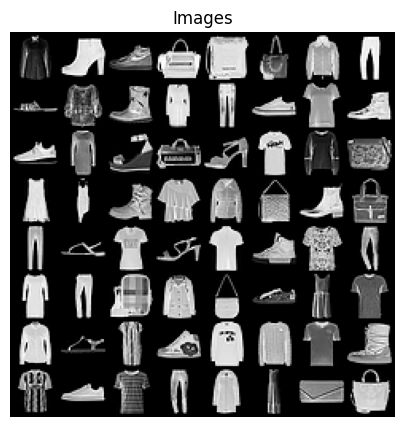

In [ ]:
def show_imgs(imgs, title="Images"):
    plt.figure(figsize=(5,5))
    plt.axis("off")
    plt.title(title)
    plt.imshow(np.transpose(vutils.make_grid(imgs, padding=2, normalize=True).cpu(),(1,2,0)))
    plt.show()

real_batch = next(iter(dataloader))[0][:64]
img_shape = real_batch[0].shape
show_imgs(real_batch)

## Definimos el modelo
Las GANs (Generative Adversarial Networks) consisten en dos redes que compiten entre sí: un generador que crea datos falsos y un discriminador que trata de distinguirlos de los datos reales, mejorando así la calidad de los datos generados con el tiempo.

### Generador
Es una red neuronal que, partiendo de un espacio latente, crea datos sintéticos con el objetivo de parecerse a los datos reales.

Esta "parte" del modelo es la que nos va a servir luego para la generación.

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim, number_feature_maps, output_channels):
        super(Generator, self).__init__()
        self.latent_feature_maps = latent_dim
        self.main = nn.Sequential(
            # Tamaño entrada (bs, tamaño latente, 1, 1)
            nn.ConvTranspose2d(latent_dim, number_feature_maps * 4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*4, 7 , 7)
            nn.ConvTranspose2d(number_feature_maps * 4, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*2, 14 , 14)
            nn.ConvTranspose2d(number_feature_maps * 2, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps, 28 , 28)
            nn.ConvTranspose2d(number_feature_maps, output_channels, 3, 1, 1, bias=False),
            nn.Tanh(),
            # Tamaño salida (bs, 1, 28 , 28)
        )

    def forward(self, input):
        result = self.main(input)
        return result

### Discriminador

Es una red neuronal que clasifica los datos como reales o generados. Su tarea es distinguir entre los datos reales y los falsos producidos por el generador, ayudando así a mejorar la calidad de ambos.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, input_channels, number_feature_maps, output_dim):
        super(Discriminator, self).__init__()
        self.conv_layers = nn.Sequential(
            # Tamaño entrada (bs, 1, 28, 28)
            nn.Conv2d(input_channels, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps, 14, 14)
            nn.Conv2d(number_feature_maps, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*2, 7, 7)
            nn.Conv2d(number_feature_maps * 2, number_feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
        )

        self.fully_connected = nn.Sequential(
            nn.Flatten(1),
            # Tamaño (bs, 3*3*number_feature_maps*4)
            nn.Linear(3*3*number_feature_maps*4, output_dim),
            nn.Sigmoid()
        )

    def forward(self, input):
        res = self.conv_layers(input)
        res = self.fully_connected(res)
        return res

## Definición de hyperparámetros y creación del modelo.

In [ ]:
# Definimos hyperparámetros
latent_dim = 100
discriminator_lr = 0.0002
generator_lr = 0.002
n_epochs = 12

# Creamos el generador y el discriminador
generator = Generator(
    latent_dim=latent_dim,
    number_feature_maps=64,
    output_channels=1
).to(device)

discriminator = Discriminator(
    input_channels=1,
    number_feature_maps=64,
    output_dim=1
).to(device)

# Definir la función de pérdida
adversarial_loss = nn.BCELoss()

In [ ]:
def train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device, verbose=False):
    generator.train()
    discriminator.train()

    # Creamos los dos optimizadores. 
    optimizer_G = optim.Adam(generator.parameters(), lr=generator_lr)
    optimizer_D = optim.Adam(discriminator.parameters(), lr=discriminator_lr)

    for epoch in tqdm(range(n_epochs)):
        for i, (imgs, _) in enumerate(dataloader):
            bs = imgs.size(0)

            # Creamos las etiquetas para el discriminador
            valid = torch.ones(bs, 1, device=device)
            fake = torch.zeros(bs, 1, device=device)

            real_imgs = imgs.to(device)

            # Creamos ruido dentro del espacio latente usando una normal
            latent_shape = (bs, generator.latent_feature_maps, 1, 1)
            z = torch.randn(latent_shape)
            z = z.to(device)

            
            # Entrenar el generador
            optimizer_G.zero_grad()

            gen_imgs = generator(z)
            g_loss = adversarial_loss(discriminator(gen_imgs), valid)

            g_loss.backward()
            optimizer_G.step()

            # Entrenar el discrminador (recordar hacer el detach de las imagenes generadas)
            optimizer_D.zero_grad()

            real_loss = adversarial_loss(discriminator(real_imgs), valid)
            fake_loss = adversarial_loss(discriminator(gen_imgs.detach()), fake)
            
            d_loss = (real_loss + fake_loss) / 2
            
            d_loss.backward()
            optimizer_D.step()

            if verbose: print(f"[Epoch {epoch}/{n_epochs}] [Batch {i}/{len(dataloader)}] [D loss: {d_loss.item()}] [G loss: {g_loss.item()}]")

        if epoch % 4 == 0:
                x = gen_imgs.detach()

                print(
                    f"G loss: {g_loss.item():.4f} | "
                    f"D loss: {d_loss.item():.4f}\n"
                    f"min: {x.min().item():.4f} | "
                    f"max: {x.max().item():.4f} | "
                    f"media: {x.mean().item():.4f} | "
                    f"std: {x.std().item():.4f}"
                )
                show_imgs(gen_imgs.detach()[:32], title=f"Epoch {epoch}")
            


## Entrenamiento del modelo

### Entrenamiento con generator learning rate = 0.002

Durante el entrenamiento se saturó desde la Epoch 0, el discriminador pudo distinguir fácilmente a las imágenes generadas por lo cual el generador no logra aprender. 
- Epoch 0: aparecen patrones repetidos. G loss = 10.5443 y D loss ≈ 0.0001: el discriminador distingue muy fácilmente las imágenes generadas.
- Epoch 4: los píxeles van de −1.0000 a −0.9984, con media −1.0000 y desviación redondeada a 0.0000. Aquí se confirma que las imágenes son prácticamente negras y uniformes, con la salida de Tanh saturada cerca de −1.
- Epoch 8: la media sigue en −0.9992. Aparecen algunos puntos aislados, pero no hay recuperación visual. G loss = 17.3194 y D loss sigue cerca de cero.

  0%|          | 0/12 [00:00<?, ?it/s]

G loss: 9.2040 | D loss: 0.0001
min: -1.0000 | max: 1.0000 | media: -0.7742 | std: 0.5489


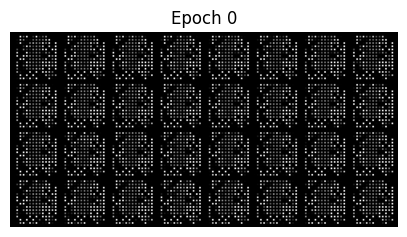

 33%|███▎      | 4/12 [00:23<00:46,  5.85s/it]

G loss: 12.5563 | D loss: 0.0000
min: -1.0000 | max: 1.0000 | media: -0.8024 | std: 0.5557


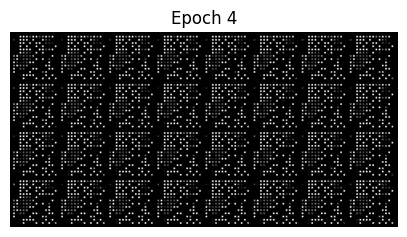

 67%|██████▋   | 8/12 [00:46<00:23,  5.82s/it]

G loss: 15.3886 | D loss: 0.0000
min: -1.0000 | max: -1.0000 | media: -1.0000 | std: 0.0000


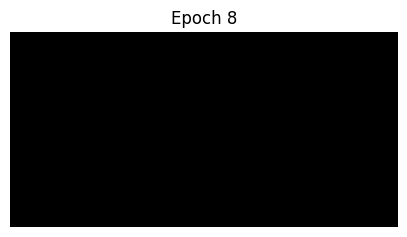

100%|██████████| 12/12 [01:10<00:00,  5.85s/it]


In [ ]:
# Comenzamos el entrenamiento del modelo!
train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device)

### Entrenamiento con generator learning rate = 0.0002

In [ ]:
# Definimos hyperparámetros
latent_dim = 100
discriminator_lr = 0.0002
generator_lr = 0.0002
n_epochs = 12

# Creamos el generador y el discriminador
generator = Generator(
    latent_dim=latent_dim,
    number_feature_maps=64,
    output_channels=1
).to(device)

discriminator = Discriminator(
    input_channels=1,
    number_feature_maps=64,
    output_dim=1
).to(device)

# Definir la función de pérdida
adversarial_loss = nn.BCELoss()

Con un learning rate del generador más bajo genera prendas reconocibles y variadas, mientras que en la corrida anterior terminaba en imágenes casi negras.

- Epoch 0: aparecen siluetas, aunque con patrones y deformaciones.
- Epoch 4: se distinguen pantalones, prendas superiores y botas.
- Epoch 8: aparecen también zapatillas y formas más definidas. Todavía hay artefactos y algunas prendas deformadas, pero ya aprendió características del dataset.

  0%|          | 0/12 [00:00<?, ?it/s]

G loss: 12.0197 | D loss: 0.0000
min: -1.0000 | max: 1.0000 | media: -0.0984 | std: 0.9829


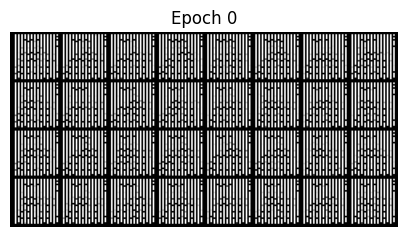

 33%|███▎      | 4/12 [00:23<00:46,  5.81s/it]

G loss: 12.4253 | D loss: 0.0000
min: -1.0000 | max: 1.0000 | media: -0.0246 | std: 0.9707


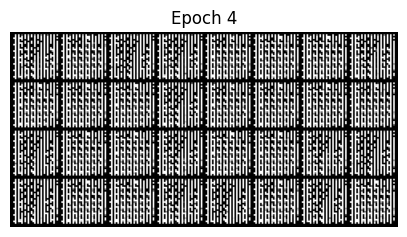

 67%|██████▋   | 8/12 [00:46<00:23,  5.81s/it]

G loss: 2.8312 | D loss: 0.1084
min: -1.0000 | max: 0.9988 | media: -0.2981 | std: 0.8000


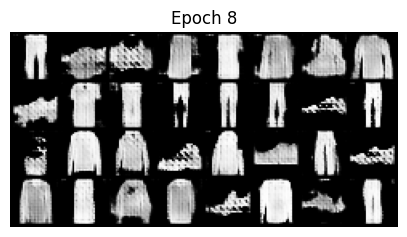

100%|██████████| 12/12 [01:09<00:00,  5.82s/it]


In [ ]:
# Comenzamos el entrenamiento del modelo!
train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device)

## Generación de datos

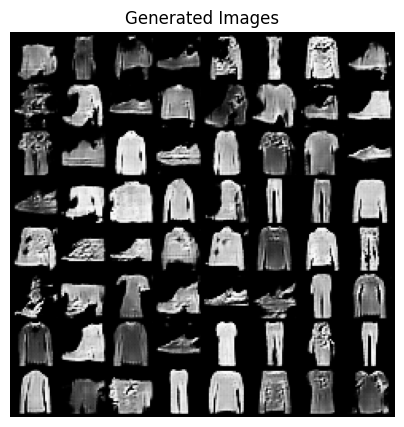

In [ ]:
def generate(generator, num_imgs=32):
    # Creamos un tensor de ruido dentro del espacio latente
    z = torch.randn(
                num_imgs, generator.latent_feature_maps, 1, 1,
                device=device
            )
    # Hacemos el forward pass del generador
    gen_imgs = generator(z)
    return gen_imgs

imgs = generate(generator, num_imgs=64)
show_imgs(imgs, title="Generated Images")

## Comparación del espacio latente: 20, 100 y 200

#### ¿En qué afecta el tamaño del espacio latente?

El tamaño del espacio latente determina cuántos números aleatorios recibe el generador para construir cada imagen. Durante el entrenamiento, el generador aprende a transformar distintos puntos de ese espacio en imágenes de prendas. Las dimensiones latentes le dan grados de libertad para representar variaciones como la forma, el ancho, las mangas, el tipo de calzado o texturas, aunque no necesariamente aprende una característica independiente por dimensión.


El tamaño puede afectar lo siguiente:

- Un espacio pequeño puede limitar la variedad que logra representar.

- Un espacio mayor permite representar variaciones de más maneras, pero el generador puede ignorar algunas dimensiones. Aumentarlo no garantiza mayor diversidad ni mejores imágenes.

In [ ]:
# Configuración independiente de los experimentos anteriores 
config_latent = {
    'latent_dims': (20, 100, 200),
    'generator_lr': 0.0002,
    'discriminator_lr': 0.0002,
    'n_epochs': 12,
    'batch_size': 64,
    'number_feature_maps': 64,
    'seed': 42,
    'num_samples': 64,
}

device_latent = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)

transform_latent = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
dataset_latent = datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform_latent
)

print(f'Comparación en {device_latent}: {len(dataset_latent)} imágenes por época')

Comparación en cuda: 60000 imágenes por época


In [ ]:
def train_latent_comparison(generator, discriminator, dataloader,
                            n_epochs, device, generator_lr=0.0002,
                            discriminator_lr=0.0002):
    """Mismo entrenamiento G -> D; devuelve pérdidas promedio por época."""
    generator.to(device).train()
    discriminator.to(device).train()
    criterion = nn.BCELoss()
    optimizer_G = optim.Adam(generator.parameters(), lr=generator_lr)
    optimizer_D = optim.Adam(discriminator.parameters(), lr=discriminator_lr)
    history = {'g_loss': [], 'd_loss': []}

    for epoch in tqdm(range(n_epochs),
                      desc=f'latent_dim={generator.latent_feature_maps}'):
        total_g = 0.0
        total_d = 0.0
        n_images = 0

        for imgs, _ in dataloader:
            real_imgs = imgs.to(device)
            bs = real_imgs.size(0)
            valid = torch.ones(bs, 1, device=device)
            fake = torch.zeros(bs, 1, device=device)
            z = torch.randn(bs, generator.latent_feature_maps, 1, 1,
                            device=device)

            # 1. Generador: buscamos una respuesta cercana a 1.
            optimizer_G.zero_grad()
            gen_imgs = generator(z)
            g_loss = criterion(discriminator(gen_imgs), valid)
            g_loss.backward()
            optimizer_G.step()

            # 2. Discriminador: reales -> 1 y generadas -> 0.
            optimizer_D.zero_grad()
            real_loss = criterion(discriminator(real_imgs), valid)
            fake_loss = criterion(discriminator(gen_imgs.detach()), fake)
            d_loss = (real_loss + fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()

            total_g += g_loss.item() * bs
            total_d += d_loss.item() * bs
            n_images += bs

        history['g_loss'].append(total_g / n_images)
        history['d_loss'].append(total_d / n_images)
        print(
            f'Época {epoch + 1}/{n_epochs} | '
            f"G promedio: {history['g_loss'][-1]:.4f} | "
            f"D promedio: {history['d_loss'][-1]:.4f}"
        )

    return history

In [ ]:
def comparar_latent_dims(dataset, device, latent_dims=(20, 100, 200),
                        generator_lr=0.0002, discriminator_lr=0.0002,
                        n_epochs=12, batch_size=64, number_feature_maps=64,
                        seed=42, num_samples=64):
    """Crea redes nuevas por dimensión y conserva cada modelo entrenado."""
    results = {}
    sample_rng = torch.Generator().manual_seed(seed + 1)
    base_noise = torch.randn(num_samples, max(latent_dims), 1, 1,
                             generator=sample_rng)

    for dim in latent_dims:
        # Discriminador primero para que su inicialización sea la misma
        # aunque la primera capa del generador tenga distinto tamaño.
        torch.manual_seed(seed)
        disc = Discriminator(
            input_channels=1,
            number_feature_maps=number_feature_maps,
            output_dim=1
        ).to(device)

        torch.manual_seed(seed)
        gen = Generator(
            latent_dim=dim,
            number_feature_maps=number_feature_maps,
            output_channels=1
        ).to(device)

        # El orden de los datos no depende del ruido ni de los pesos.
        data_rng = torch.Generator().manual_seed(seed)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,
                            generator=data_rng, num_workers=0)
        torch.manual_seed(seed + 2)

        print(f'\nEntrenando desde cero: latent_dim={dim}')
        history = train_latent_comparison(
            gen, disc, loader, n_epochs=n_epochs, device=device,
            generator_lr=generator_lr, discriminator_lr=discriminator_lr
        )

        gen.eval()
        # Usamos ruido fijo; las primeras coordenadas son compartidas.
        # Esto no implica que las imágenes de una misma posición sean
        # la misma prenda en modelos entrenados por separado.
        fixed_noise = base_noise[:, :dim].contiguous().to(device)
        with torch.no_grad():
            samples = gen(fixed_noise).cpu()

        results[dim] = {
            'generator': gen.cpu(),
            'history': history,
            'samples': samples,
        }
        # No necesitamos conservar el discriminador para generar imágenes.
        del disc, fixed_noise

    return results

In [ ]:
# Esta celda ejecuta las tres corridas, cada una con redes y optimizadores nuevos.
resultados_latent = comparar_latent_dims(
    dataset_latent, device_latent, **config_latent
)


Entrenando desde cero: latent_dim=20


latent_dim=20:   0%|          | 0/12 [00:00<?, ?it/s]

latent_dim=20:   8%|▊         | 1/12 [00:06<01:14,  6.76s/it]

Época 1/12 | G promedio: 3.9343 | D promedio: 0.1097


latent_dim=20:  17%|█▋        | 2/12 [00:13<01:07,  6.74s/it]

...

Época 10/12 | G promedio: 2.7440 | D promedio: 0.2032


latent_dim=200:  92%|█████████▏| 11/12 [01:44<00:09,  9.53s/it]

Época 11/12 | G promedio: 2.7122 | D promedio: 0.2121


latent_dim=200: 100%|██████████| 12/12 [01:54<00:00,  9.54s/it]

Época 12/12 | G promedio: 2.5951 | D promedio: 0.2244


Al aumentar latent_dim de 20 a 200 no produjo una mejora visual importante. En las imágenes generadas, los 3 producen una variedad de prendas y se notan que hay deformaciones también. Aunque en latent_dim = 200 las prendas parecen un poco más nítidas.

En cuanto a las curvas de loss del generador: el modelo de 20 dimensiones tuvo el comienzo más inestable con una pérdida de aprox 9,1 en la segunda época pero luego se recuperó. Los tres terminan con pérdidas del generador similar. 

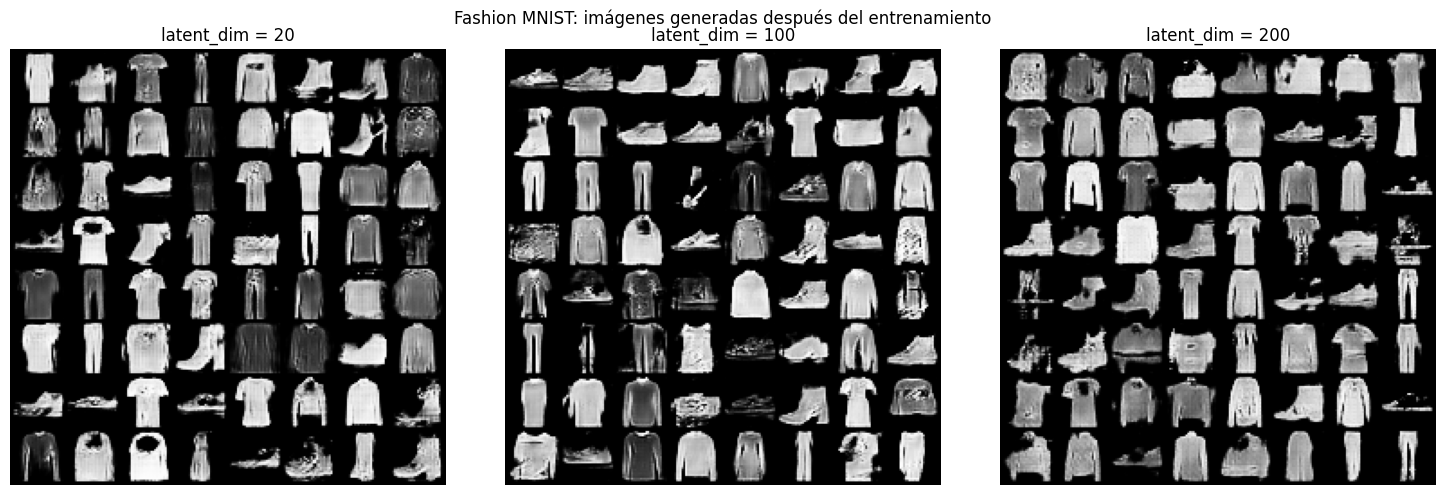

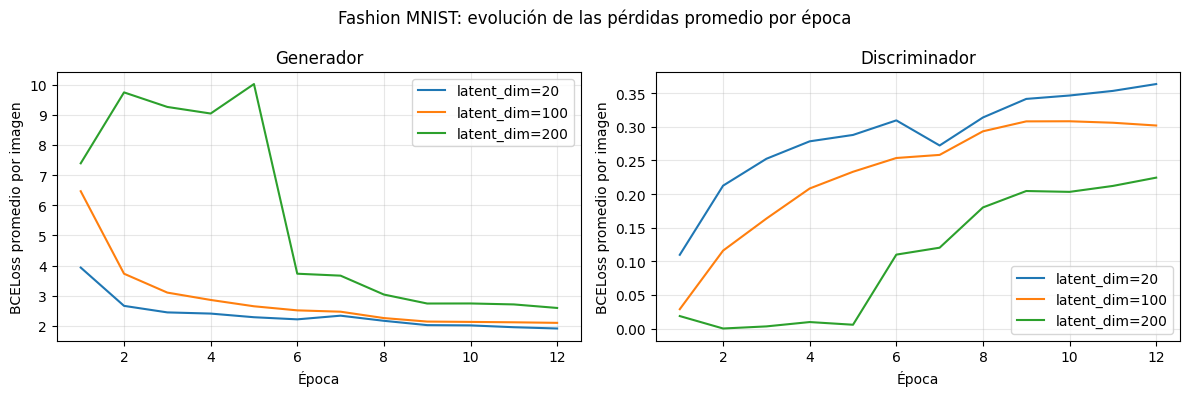

In [ ]:
def mostrar_comparacion_latent(results):
    dims = list(results)
    fig, axes = plt.subplots(1, len(dims), figsize=(5 * len(dims), 5),
                             squeeze=False)
    for ax, dim in zip(axes[0], dims):
        # Escala fija para comparar los píxeles, sin ajustar el contraste
        # de cada modelo por separado.
        grid = vutils.make_grid(results[dim]['samples'], nrow=8, padding=2,
                                normalize=True, value_range=(-1, 1))
        ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
        ax.set_title(f'latent_dim = {dim}')
        ax.axis('off')
    fig.suptitle('Fashion MNIST: imágenes generadas después del entrenamiento')
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for dim in dims:
        history = results[dim]['history']
        epochs = range(1, len(history['g_loss']) + 1)
        axes[0].plot(epochs, history['g_loss'], label=f'latent_dim={dim}')
        axes[1].plot(epochs, history['d_loss'], label=f'latent_dim={dim}')

    for ax, title in zip(axes, ('Generador', 'Discriminador')):
        ax.set_title(title)
        ax.set_xlabel('Época')
        ax.set_ylabel('BCELoss promedio por imagen')
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle('Fashion MNIST: evolución de las pérdidas promedio por época')
    plt.tight_layout()
    plt.show()


mostrar_comparacion_latent(resultados_latent)

#### ¿Por qué entrenamos al discriminador y al generador alternativamente?

Se entrenan por turnos porque:

1. **Para que aprendan juntos paso a paso:**
   El generador no ve los datos reales; solo aprende según las correcciones que le da el discriminador. Para que esa guía sea útil, el discriminador debe ir actualizándose a medida que el generador inventa nuevas falsificaciones.
2. **Para evitar que el discriminador sea "invencible":**
   Si el discriminador se entrena demasiado tiempo sin que el generador cambie, se vuelve perfecto identificando cualquier falla y rechaza todo. Cuando el discriminador es inflexible, deja de darle pistas útiles al generador sobre cómo mejorar. Esto fue lo que sucedió en el primer entrenamiento con generator_lr más alto que el discriminator_lr, el generador no pudo aprender por tener un discriminador muy bueno haciendo su trabajo.
3. **Para evitar que el generador descubra una "trampa fácil":**
   Si el generador se entrena demasiado contra un discriminador desactualizado, el generador aprende un único truco simple para engañarlo y se queda repitiendo siempre la misma imagen (*colapso de modo*), en lugar de aprender a generar variedad.

Al alternar pequeños pasos entre ambos, ninguno domina por completo al otro y avanzan en equilibrio hasta que el generador produce muestras indistinguibles de las reales.

#### ¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?

El tamaño de salida del discriminador es: (bs, 1): un valor por cada imagen del batch. Su última capa sigmoid transforma la salida en un valor entre 0 y 1 que expresa qué tan problable considera que la imagen sea real. 
El tamaño de salida del generador es: (bs, 1, 28 , 28), esto es porque el generador crea una imagen a partir de ruido.

#### ¿Qué tipo de activación final se usa en el discriminador y por qué?
Se usa la función sigmoid porque el discriminador clasifica si la imagen es falsa o real.

#### ¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.


El propósito de la competencia en las GANs es permitir que el modelo aprenda a generar datos sintéticos realistas sin necesidad de definir ni evaluar una función de probabilidad explícita sobre los datos.


**¿Cómo contribuye esta competencia a la mejora del modelo?**

1. El generador no tiene acceso directo a los datos reales; su única forma de aprender es a través de los gradientes que se propagan desde el discriminador.
2. **Ciclo de retroalimentación dinámica:** 
   * Cuando \\(D\\) aprende a detectar los defectos en las muestras sintéticas, le proporciona a \\(G\\) una señal de gradiente específica que le indica en qué dirección modificar sus parámetros para corregir esos errores.
   * Conforme \\(G\\) mejora y produce muestras más creíbles, obliga a \\(D\\) a refinar sus criterios para encontrar imperfecciones cada vez más sutiles.
3. **Convergencia al equilibrio óptimo:** Esta rivalidad mutua impulsa el entrenamiento hasta alcanzar un punto donde la distribución generada imita a la real. En este estado de equilibrio, las falsificaciones son tan realistas que el discriminador ya no puede diferenciar entre lo real y lo sintético.


#### Entrene una GAN que genere imágenes del dataset [SVHN (street view house number)](http://ufldl.stanford.edu/housenumbers/).

Estas imágenes son de (3, 32, 32). Debe crear un nuevo generador y dicriminador para ajustarse a estas nuevas dimensiones.

Image size: torch.Size([3, 32, 32])


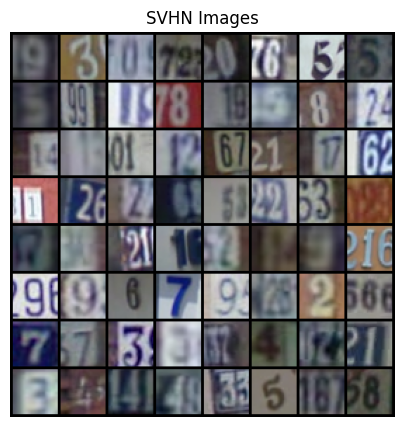

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(0, 1)
    ])

dataset = datasets.SVHN(root='./data', download=True, transform=transform)  
print(f"Image size: {dataset[0][0].shape}")

batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)
real_batch = next(iter(dataloader))[0]
img_shape = real_batch[0].shape
show_imgs(real_batch, "SVHN Images")

## GAN para SVHN: imágenes RGB de 32 × 32

En el transform definido por la letra hace que los píxeles reales permanecen
en `[0, 1]`. Por eso este generador termina en **Sigmoid**, cuya salida
también está entre 0 y 1.

El generador transforma `(bs, latent_dim, 1, 1)` en `(bs, 3, 32, 32)`.
El discriminador recibe `(bs, 3, 32, 32)` y devuelve `(bs, 1)`.
Las etiquetas de los dígitos no se usan: esta GAN aprende a generar imágenes
sin condicionar la generación a una clase.

In [ ]:
class GeneratorSVHN(nn.Module):
    def __init__(self, latent_dim=100, number_feature_maps=64):
        super().__init__()
        self.latent_dim = latent_dim
        f = number_feature_maps

        self.main = nn.Sequential(
            # (bs, latent_dim, 1, 1) -> (bs, 4*f, 4, 4)
            nn.ConvTranspose2d(latent_dim, 4 * f, 4, 1, 0, bias=False),
            nn.BatchNorm2d(4 * f),
            nn.ReLU(inplace=True),

            # (bs, 4*f, 4, 4) -> (bs, 2*f, 8, 8)
            nn.ConvTranspose2d(4 * f, 2 * f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(2 * f),
            nn.ReLU(inplace=True),

            # (bs, 2*f, 8, 8) -> (bs, f, 16, 16)
            nn.ConvTranspose2d(2 * f, f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f),
            nn.ReLU(inplace=True),

            # (bs, f, 16, 16) -> (bs, 3, 32, 32)
            nn.ConvTranspose2d(f, 3, 4, 2, 1, bias=False),
            nn.Sigmoid()  # Píxeles en [0, 1], igual que las imágenes reales
        )

    def forward(self, z):
        return self.main(z)

In [ ]:
class DiscriminatorSVHN(nn.Module):
    def __init__(self, number_feature_maps=64):
        super().__init__()
        f = number_feature_maps

        self.main = nn.Sequential(
            # (bs, 3, 32, 32) -> (bs, f, 16, 16)
            nn.Conv2d(3, f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f),
            nn.LeakyReLU(0.2, inplace=True),

            # (bs, f, 16, 16) -> (bs, 2*f, 8, 8)
            nn.Conv2d(f, 2 * f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(2 * f),
            nn.LeakyReLU(0.2, inplace=True),

            # (bs, 2*f, 8, 8) -> (bs, 4*f, 4, 4)
            nn.Conv2d(2 * f, 4 * f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(4 * f),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(1),
            nn.Linear(4 * f * 4 * 4, 1),
            nn.Sigmoid()  # Una probabilidad de ser real por imagen
        )

    def forward(self, imgs):
        return self.main(imgs)

### Entrenamiento alternado

En cada batch entrenamos al discriminador con imágenes reales (objetivo 1)
y generadas (objetivo 0). `detach()` impide que ese paso actualice el generador.
Luego entrenamos al generador buscando que el discriminador responda 1.

Durante este segundo paso desactivamos los gradientes de los parámetros del
discriminador, pero el gradiente sigue pasando por sus operaciones hasta el
generador. `BCELoss` recibe probabilidades porque el discriminador termina
en `Sigmoid`.

Para seguir la evolución visual usamos siempre los mismos vectores de ruido.
Las pérdidas se promedian por época; por sí solas no garantizan imágenes de calidad.

In [ ]:
def train_svhn(generator, discriminator, dataloader, n_epochs, device,
               generator_lr=0.0002, discriminator_lr=0.0002,
               show_every=4):
    generator.to(device).train()
    discriminator.to(device).train()

    criterion = nn.BCELoss()
    optimizer_G = optim.Adam(
        generator.parameters(), lr=generator_lr, betas=(0.5, 0.999)
    )
    optimizer_D = optim.Adam(
        discriminator.parameters(), lr=discriminator_lr, betas=(0.5, 0.999)
    )

    fixed_noise = torch.randn(32, generator.latent_dim, 1, 1, device=device)
    history = {'g_loss': [], 'd_loss': []}

    for epoch in tqdm(range(n_epochs), desc='Entrenamiento SVHN'):
        total_g_loss = 0.0
        total_d_loss = 0.0
        n_images = 0

        for imgs, _ in dataloader:
            real_imgs = imgs.to(device)
            bs = real_imgs.size(0)
            valid = torch.ones(bs, 1, device=device)
            fake = torch.zeros(bs, 1, device=device)

            z = torch.randn(bs, generator.latent_dim, 1, 1, device=device)
            gen_imgs = generator(z)

            # 1. Discriminador: reales -> 1; generadas -> 0
            optimizer_D.zero_grad()
            real_loss = criterion(discriminator(real_imgs), valid)
            fake_loss = criterion(discriminator(gen_imgs.detach()), fake)
            d_loss = (real_loss + fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()

            # 2. Generador: buscamos que sus imágenes reciban un 1
            discriminator.requires_grad_(False)
            optimizer_G.zero_grad()
            g_loss = criterion(discriminator(gen_imgs), valid)
            g_loss.backward()
            optimizer_G.step()
            discriminator.requires_grad_(True)

            total_g_loss += g_loss.item() * bs
            total_d_loss += d_loss.item() * bs
            n_images += bs

        history['g_loss'].append(total_g_loss / n_images)
        history['d_loss'].append(total_d_loss / n_images)
        print(
            f"Época {epoch + 1}/{n_epochs} | "
            f"D: {history['d_loss'][-1]:.4f} | "
            f"G: {history['g_loss'][-1]:.4f}"
        )

        if show_every and ((epoch + 1) % show_every == 0 or epoch == n_epochs - 1):
            generator.eval()
            with torch.no_grad():
                samples = generator(fixed_noise).cpu()
            generator.train()
            show_imgs(samples, title=f'SVHN - época {epoch + 1}')

    return history

Entrenando SVHN en cuda


Entrenamiento SVHN:   0%|          | 0/12 [00:00<?, ?it/s]

Entrenamiento SVHN:   8%|▊         | 1/12 [00:08<01:28,  8.02s/it]

Época 1/12 | D: 0.2618 | G: 3.2019


Entrenamiento SVHN:  17%|█▋        | 2/12 [00:15<01:18,  7.89s/it]

Época 2/12 | D: 0.3236 | G: 2.5833


Entrenamiento SVHN:  25%|██▌       | 3/12 [00:23<01:10,  7.87s/it]

Época 3/12 | D: 0.2395 | G: 3.2603
Época 4/12 | D: 0.1700 | G: 4.0789


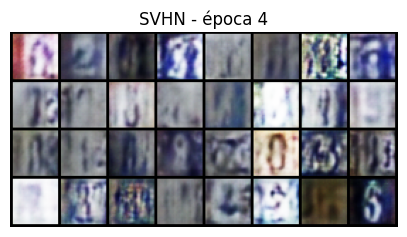

Entrenamiento SVHN:  42%|████▏     | 5/12 [00:39<00:54,  7.81s/it]

Época 5/12 | D: 0.1457 | G: 4.0764


Entrenamiento SVHN:  50%|█████     | 6/12 [00:46<00:46,  7.78s/it]

Época 6/12 | D: 0.1357 | G: 4.2218


Entrenamiento SVHN:  58%|█████▊    | 7/12 [00:54<00:38,  7.76s/it]

Época 7/12 | D: 0.1264 | G: 4.0163
Época 8/12 | D: 0.1348 | G: 3.9833


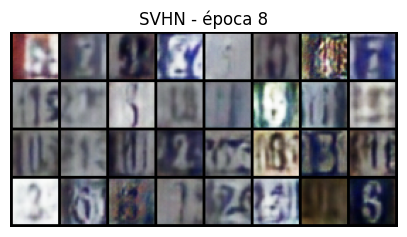

Entrenamiento SVHN:  75%|███████▌  | 9/12 [01:10<00:23,  7.80s/it]

Época 9/12 | D: 0.1275 | G: 4.2025


Entrenamiento SVHN:  83%|████████▎ | 10/12 [01:18<00:15,  7.79s/it]

Época 10/12 | D: 0.1462 | G: 3.8646


Entrenamiento SVHN:  92%|█████████▏| 11/12 [01:25<00:07,  7.77s/it]

Época 11/12 | D: 0.1702 | G: 3.7811
Época 12/12 | D: 0.1423 | G: 4.1379


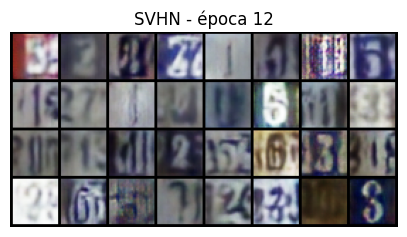

Entrenamiento SVHN: 100%|██████████| 12/12 [01:33<00:00,  7.80s/it]


In [ ]:
device_svhn = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)

latent_dim_svhn = 100
n_epochs_svhn = 12

generator_svhn = GeneratorSVHN(latent_dim=latent_dim_svhn).to(device_svhn)
discriminator_svhn = DiscriminatorSVHN().to(device_svhn)

print(f'Entrenando SVHN en {device_svhn}')
history_svhn = train_svhn(
    generator_svhn,
    discriminator_svhn,
    dataloader,
    n_epochs=n_epochs_svhn,
    device=device_svhn
)

Imágenes generadas: (64, 3, 32, 32)


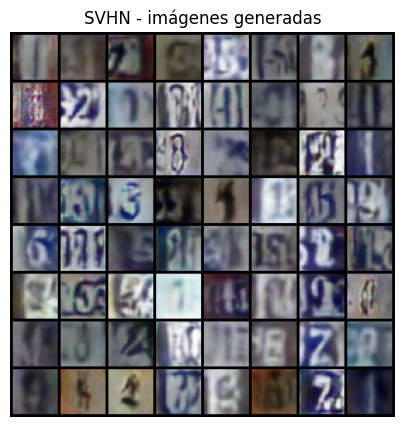

In [ ]:
def generate_svhn(generator, num_imgs=64):
    device = next(generator.parameters()).device
    was_training = generator.training
    generator.eval()
    with torch.no_grad():
        z = torch.randn(num_imgs, generator.latent_dim, 1, 1, device=device)
        imgs = generator(z).cpu()
    generator.train(was_training)
    return imgs


imgs_svhn = generate_svhn(generator_svhn, num_imgs=64)
print(f'Imágenes generadas: {tuple(imgs_svhn.shape)}')
show_imgs(imgs_svhn, title='SVHN - imágenes generadas')

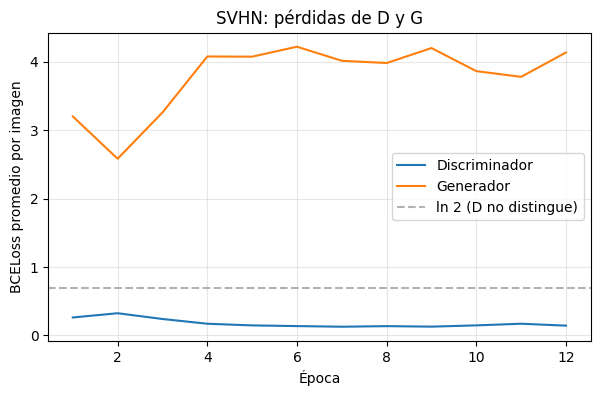

In [ ]:
epochs = range(1, len(history_svhn['g_loss']) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history_svhn['d_loss'], label='Discriminador')
plt.plot(epochs, history_svhn['g_loss'], label='Generador')
plt.axhline(math.log(2), color='gray', ls='--', alpha=0.6, label='ln 2 (D no distingue)')
plt.xlabel('Época')
plt.ylabel('BCELoss promedio por imagen')
plt.title('SVHN: pérdidas de D y G')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Resultados con SVHN

En este ciclo de entrenamiento, nuestra GAN aprendió ciertas características generales de nuestro set de datos. Las imagenes son más complejas con respecto al caso anterior, ya que tienen más tonos de grises y colores, junto con mayor constraste y representaciones de números (esto con cierta calidad para distinguir algunos numeros, no para todos). 

A simple vista, aunque es capaz de generar numeros, la calidad de los resultados es menor respecto a Fashon MNIST, ya que tenemos máyor cantidad de resultados borrosos o sin una forma clara. Esto puede deberse a que estamos trabajando con imagenes RGB más grandes, lo cual aumenta la variabilidad de nuestro set de entrenamiento.

**Curvas de pérdida.** Discriminador mantiene pérdida de 0.15 desde la época 4, mientras que la del generador esta entre 3.8 y 4.2. En un equilibrio ideal ambas deberían parecerse a la linea punteada de "ln 2", por lo que el entrenamiento no llegó a ese punto aún, dicho de otra forma: el discriminador distingue las imágenes generadas con facilidad y le da al generador poca información útil para mejorar.

A diferencia del primer experimento con Fashion MNIST, aquí el entrenamiento es más estable, ya que no hay colapso ni divergencia. El generador logra aprender algo de la distribución, pero queda por detrás del discriminador.